In [1]:
## import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

In [2]:
## Read the dataset
df = pd.read_excel("online_course_recommendation_v2.xlsx")

In [3]:
df

,user_id,course_id,course_name,instructor,course_duration_hours,certification_offered,difficulty_level,rating,enrollment_numbers,course_price,feedback_score,study_material_available,time_spent_hours,previous_courses_taken
0,15796,9366,Python for Beginners,Emma Harris,39.1,Yes,Beginner,5.0,21600,317.50,0.797,Yes,17.60,4
1,861,1928,Cybersecurity for Professionals,Alexander Young,36.3,Yes,Beginner,4.3,15379,40.99,0.770,Yes,28.97,9
2,38159,9541,DevOps and Continuous Deployment,Dr. Mia Walker,13.4,Yes,Beginner,3.9,6431,380.81,0.772,Yes,52.44,4
3,44733,3708,Project Management Fundamentals,Benjamin Lewis,58.3,Yes,Beginner,3.1,48245,342.80,0.969,No,22.29,6
4,11285,3361,Ethical Hacking Masterclass,Daniel White,30.8,Yes,Beginner,2.8,34556,381.01,0.555,Yes,22.01,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,10647,5466,Graphic Design with Canva,Emma Harris,17.3,Yes,Beginner,3.9,49101,485.34,0.838,Yes,16.35,3
99996,13800,2623,Stock Market and Trading Strategies,Dr. John Smith,68.4,Yes,Beginner,3.5,35107,162.80,0.922,Yes,41.94,7
99997,47131,1556,Networking and System Administration,Dr. John Smith,73.8,Yes,Beginner,4.3,12146,24.02,0.990,Yes,15.87,5
99998,49654,6001,Graphic Design with Canva,Daniel White,30.3,Yes,Beginner,3.5,9933,402.24,0.630,Yes,21.05,4


In [4]:
df.head()

,user_id,course_id,course_name,instructor,course_duration_hours,certification_offered,difficulty_level,rating,enrollment_numbers,course_price,feedback_score,study_material_available,time_spent_hours,previous_courses_taken
0,15796,9366,Python for Beginners,Emma Harris,39.1,Yes,Beginner,5.0,21600,317.50,0.797,Yes,17.60,4
1,861,1928,Cybersecurity for Professionals,Alexander Young,36.3,Yes,Beginner,4.3,15379,40.99,0.770,Yes,28.97,9
2,38159,9541,DevOps and Continuous Deployment,Dr. Mia Walker,13.4,Yes,Beginner,3.9,6431,380.81,0.772,Yes,52.44,4
3,44733,3708,Project Management Fundamentals,Benjamin Lewis,58.3,Yes,Beginner,3.1,48245,342.80,0.969,No,22.29,6
4,11285,3361,Ethical Hacking Masterclass,Daniel White,30.8,Yes,Beginner,2.8,34556,381.01,0.555,Yes,22.01,5


In [5]:
##Check Important Columns
df.columns

Index(['user_id', 'course_id', 'course_name', 'instructor',
       'course_duration_hours', 'certification_offered', 'difficulty_level',
       'rating', 'enrollment_numbers', 'course_price', 'feedback_score',
       'study_material_available', 'time_spent_hours',
       'previous_courses_taken'],
      dtype='object')

In [6]:
df.shape

(100000, 14)

In [7]:
##check dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 14 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   user_id                   100000 non-null  int64  
 1   course_id                 100000 non-null  int64  
 2   course_name               100000 non-null  object 
 3   instructor                100000 non-null  object 
 4   course_duration_hours     100000 non-null  float64
 5   certification_offered     100000 non-null  object 
 6   difficulty_level          100000 non-null  object 
 7   rating                    100000 non-null  float64
 8   enrollment_numbers        100000 non-null  int64  
 9   course_price              100000 non-null  float64
 10  feedback_score            100000 non-null  float64
 11  study_material_available  100000 non-null  object 
 12  time_spent_hours          100000 non-null  float64
 13  previous_courses_taken    100000 non-null  in

In [8]:
## find missing values
df.isnull().sum()

user_id                     0
course_id                   0
course_name                 0
instructor                  0
course_duration_hours       0
certification_offered       0
difficulty_level            0
rating                      0
enrollment_numbers          0
course_price                0
feedback_score              0
study_material_available    0
time_spent_hours            0
previous_courses_taken      0
dtype: int64

In [9]:
##check duplicate values
df.duplicated().sum()

np.int64(0)

In [10]:
## check statistics
df.describe()

,user_id,course_id,course_duration_hours,rating,enrollment_numbers,course_price,feedback_score,time_spent_hours,previous_courses_taken
count,100000.000000,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,24935.663570,5006.863560,52.38354,3.959859,25052.822850,261.073369,0.746865,20.691054,4.992670
std,14406.960108,2882.085456,27.42347,0.729958,14388.188356,139.013758,0.143683,13.669148,2.237259
min,1.000000,1.000000,5.00000,1.000000,50.000000,20.000000,0.092000,1.000000,0.000000
25%,12487.750000,2523.000000,28.60000,3.500000,12583.750000,140.100000,0.649000,9.900000,3.000000
50%,24793.500000,5012.000000,52.40000,4.000000,25057.500000,262.310000,0.750000,19.920000,5.000000
75%,37382.250000,7502.000000,76.10000,4.500000,37522.000000,381.702500,0.851000,30.080000,6.000000
max,49999.000000,9999.000000,100.00000,5.000000,49999.000000,500.000000,1.000000,84.150000,19.000000


In [11]:
## check unique values
df.nunique()

user_id                     43242
course_id                    9998
course_name                    20
instructor                     20
course_duration_hours         951
certification_offered           2
difficulty_level                3
rating                         41
enrollment_numbers          43085
course_price                41999
feedback_score                780
study_material_available        2
time_spent_hours             5978
previous_courses_taken         19
dtype: int64

In [12]:
##check datatypes
df.dtypes

user_id                       int64
course_id                     int64
course_name                  object
instructor                   object
course_duration_hours       float64
certification_offered        object
difficulty_level             object
rating                      float64
enrollment_numbers            int64
course_price                float64
feedback_score              float64
study_material_available     object
time_spent_hours            float64
previous_courses_taken        int64
dtype: object

In [13]:
df.to_csv("clean_data.csv",index=False)
df

,user_id,course_id,course_name,instructor,course_duration_hours,certification_offered,difficulty_level,rating,enrollment_numbers,course_price,feedback_score,study_material_available,time_spent_hours,previous_courses_taken
0,15796,9366,Python for Beginners,Emma Harris,39.1,Yes,Beginner,5.0,21600,317.50,0.797,Yes,17.60,4
1,861,1928,Cybersecurity for Professionals,Alexander Young,36.3,Yes,Beginner,4.3,15379,40.99,0.770,Yes,28.97,9
2,38159,9541,DevOps and Continuous Deployment,Dr. Mia Walker,13.4,Yes,Beginner,3.9,6431,380.81,0.772,Yes,52.44,4
3,44733,3708,Project Management Fundamentals,Benjamin Lewis,58.3,Yes,Beginner,3.1,48245,342.80,0.969,No,22.29,6
4,11285,3361,Ethical Hacking Masterclass,Daniel White,30.8,Yes,Beginner,2.8,34556,381.01,0.555,Yes,22.01,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,10647,5466,Graphic Design with Canva,Emma Harris,17.3,Yes,Beginner,3.9,49101,485.34,0.838,Yes,16.35,3
99996,13800,2623,Stock Market and Trading Strategies,Dr. John Smith,68.4,Yes,Beginner,3.5,35107,162.80,0.922,Yes,41.94,7
99997,47131,1556,Networking and System Administration,Dr. John Smith,73.8,Yes,Beginner,4.3,12146,24.02,0.990,Yes,15.87,5
99998,49654,6001,Graphic Design with Canva,Daniel White,30.3,Yes,Beginner,3.5,9933,402.24,0.630,Yes,21.05,4


## Data cleaning summary

- Dataset loaded successfully.
- The dataset contains 14 rows and 100000 columns.
- No duplicate records were found.
- Missing values were handled successfully.
- Numerical and categorical columns were identified.
- Cleaned dataset was saved for further analysis.

In [14]:
df.select_dtypes(include=['int64','float64']).columns

Index(['user_id', 'course_id', 'course_duration_hours', 'rating',
       'enrollment_numbers', 'course_price', 'feedback_score',
       'time_spent_hours', 'previous_courses_taken'],
      dtype='object')

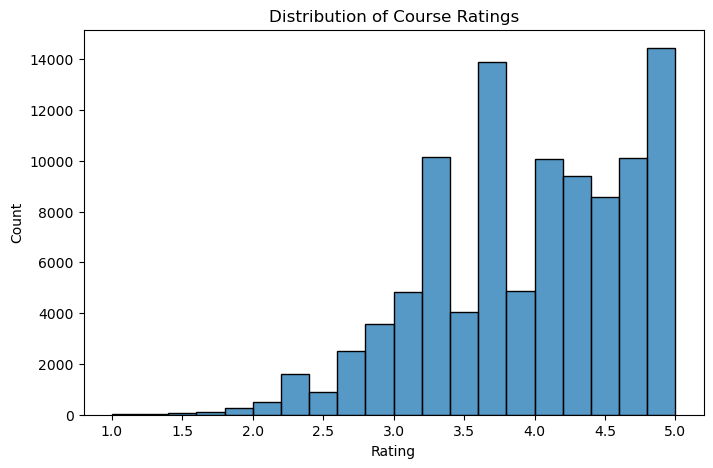

In [15]:
##Rating destribution
plt.figure(figsize=(8,5))
sns.histplot(df['rating'], bins=20)
plt.title("Distribution of Course Ratings")
plt.xlabel("Rating")
plt.ylabel("Count")
plt.show()

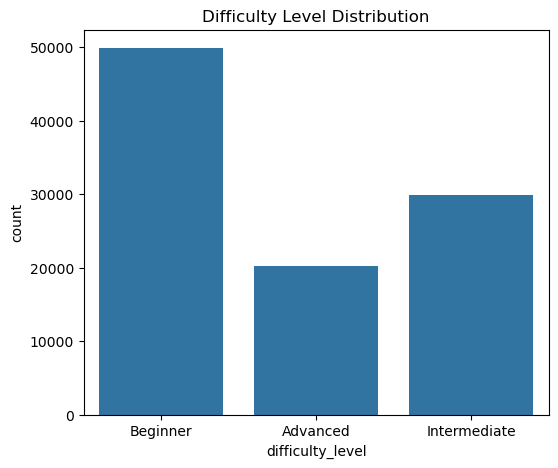

In [16]:
## difficulty level distribution
plt.figure(figsize=(6,5))
sns.countplot(data=df, x='difficulty_level')
plt.title("Difficulty Level Distribution")
plt.show()

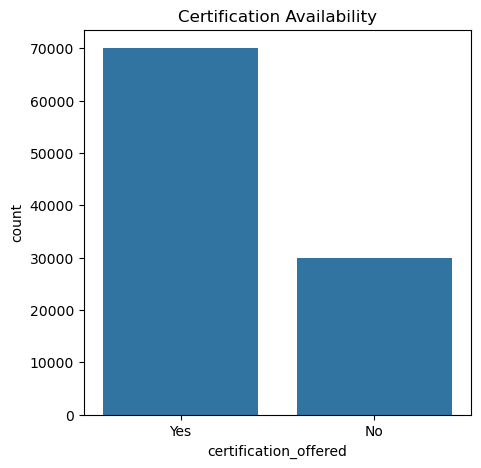

In [17]:
##Certification availability
plt.figure(figsize=(5,5))
sns.countplot(data=df, x='certification_offered')
plt.title("Certification Availability")
plt.show()

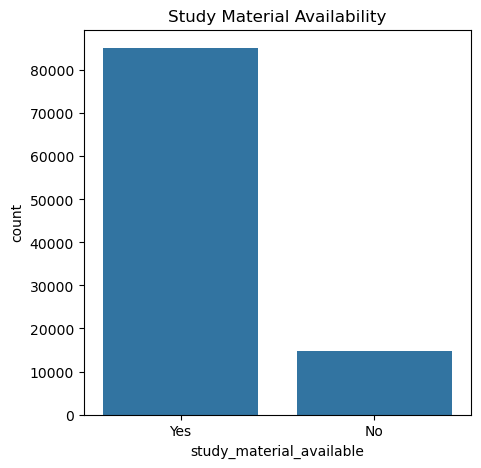

In [18]:
##study material availability
plt.figure(figsize=(5,5))
sns.countplot(data=df, x='study_material_available')
plt.title("Study Material Availability")
plt.show()

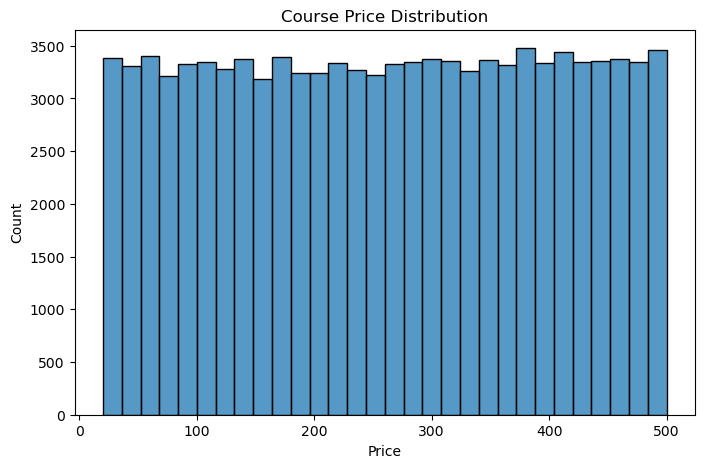

In [19]:
##course price distribution
plt.figure(figsize=(8,5))
sns.histplot(df['course_price'], bins=30)
plt.title("Course Price Distribution")
plt.xlabel("Price")
plt.show()

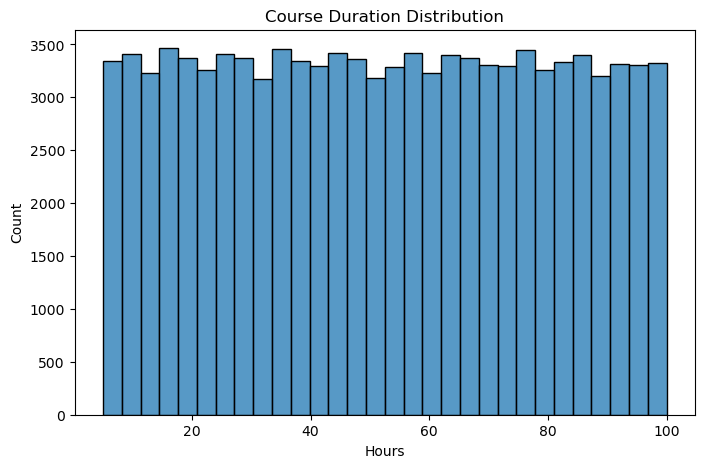

In [20]:
##course duration distribution
plt.figure(figsize=(8,5))
sns.histplot(df['course_duration_hours'], bins=30)
plt.title("Course Duration Distribution")
plt.xlabel("Hours")
plt.show()

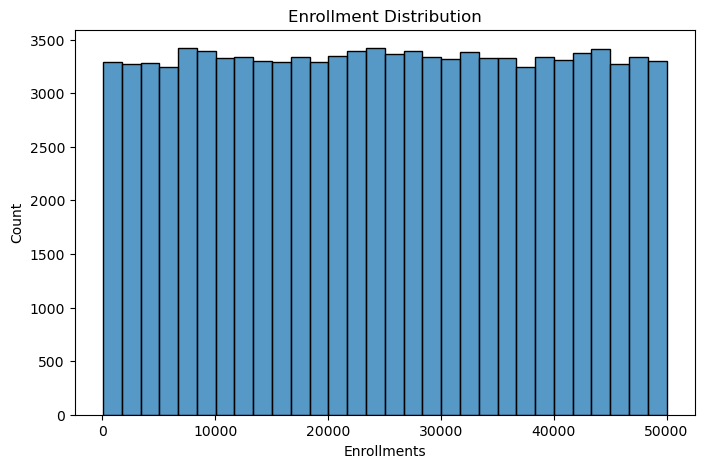

In [21]:
##Enrollment Numbers Distribution
plt.figure(figsize=(8,5))
sns.histplot(df['enrollment_numbers'], bins=30)
plt.title("Enrollment Distribution")
plt.xlabel("Enrollments")
plt.show()

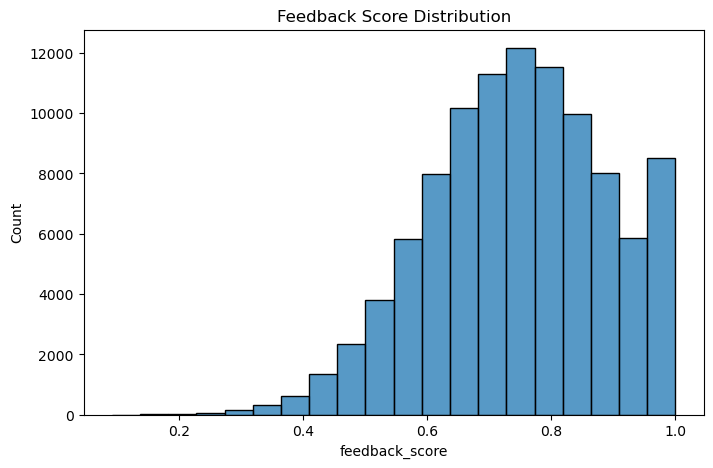

In [22]:
##Feedback Score Distribution
plt.figure(figsize=(8,5))
sns.histplot(df['feedback_score'], bins=20)
plt.title("Feedback Score Distribution")
plt.show()

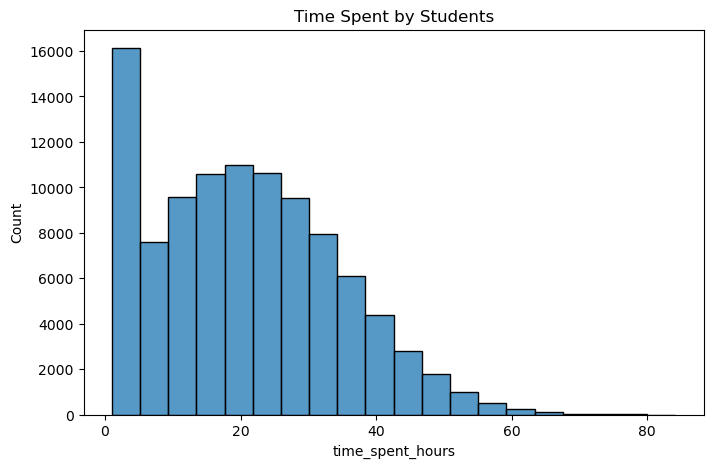

In [23]:
##Time Spent Distribution
plt.figure(figsize=(8,5))
sns.histplot(df['time_spent_hours'], bins=20)
plt.title("Time Spent by Students")
plt.show()

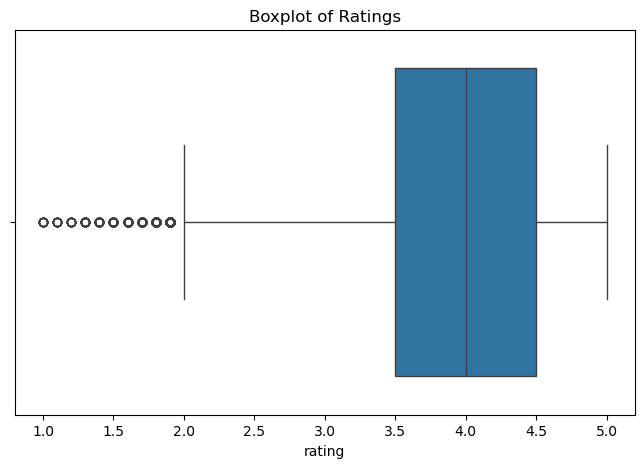

In [24]:
##Boxplot for Rating
plt.figure(figsize=(8,5))
sns.boxplot(x=df['rating'])
plt.title("Boxplot of Ratings")
plt.show()

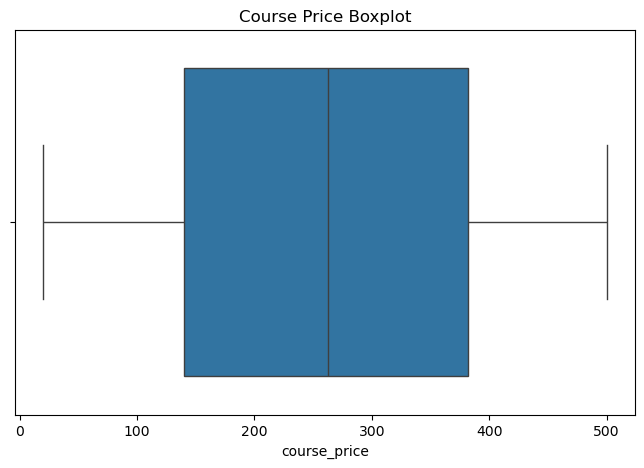

In [25]:
##Boxplot for Price
plt.figure(figsize=(8,5))
sns.boxplot(x=df['course_price'])
plt.title("Course Price Boxplot")
plt.show()

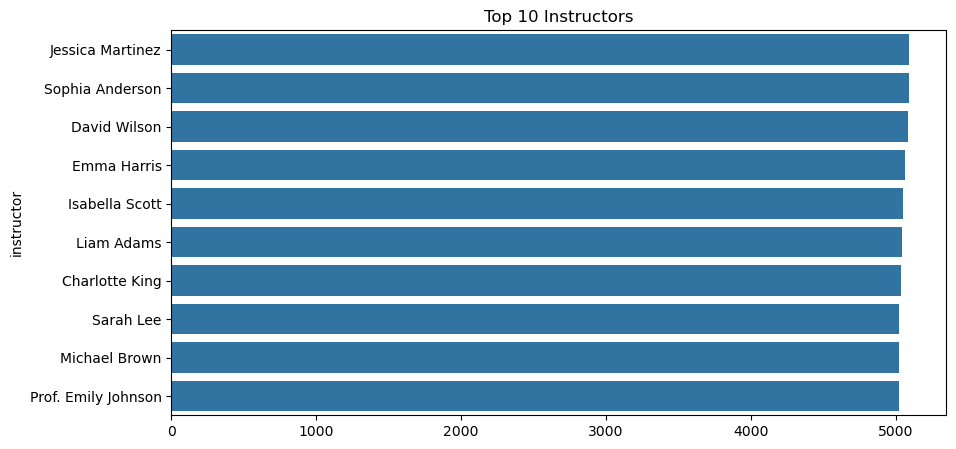

In [26]:
##Top 10 Instructors
top = df['instructor'].value_counts().head(10)
plt.figure(figsize=(10,5))
sns.barplot(x=top.values, y=top.index)
plt.title("Top 10 Instructors")
plt.show()

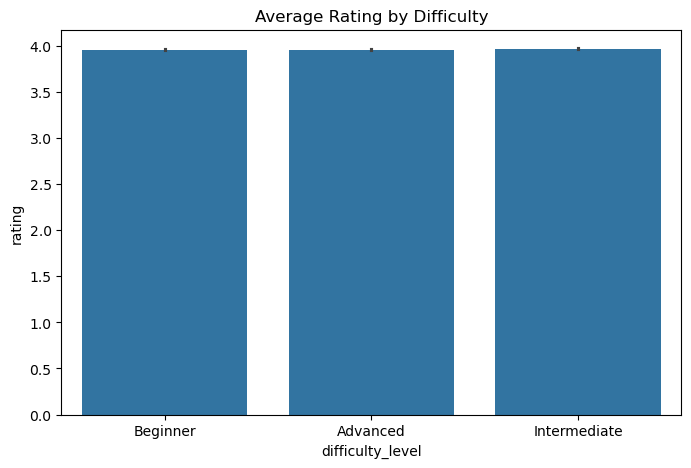

In [27]:
##Average Rating by Difficulty
plt.figure(figsize=(8,5))
sns.barplot(data=df,
            x='difficulty_level',
            y='rating')
plt.title("Average Rating by Difficulty")
plt.show()

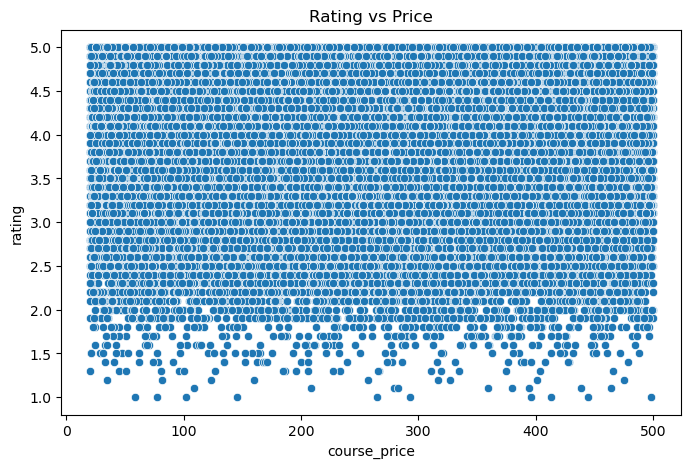

In [28]:
##Rating vs Course Price
plt.figure(figsize=(8,5))
sns.scatterplot(data=df,
                x='course_price',
                y='rating')
plt.title("Rating vs Price")
plt.show()

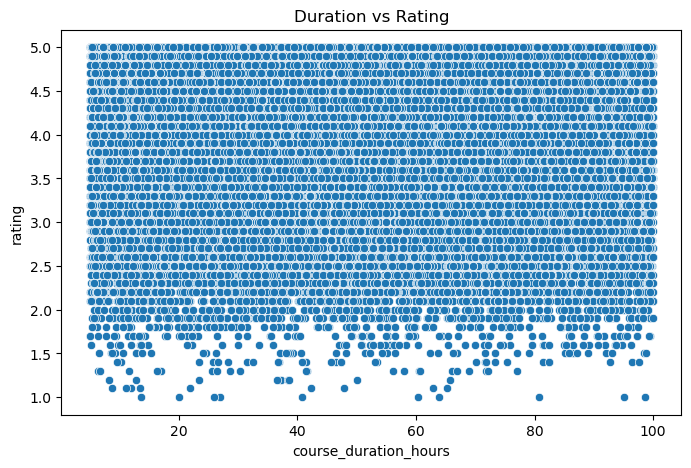

In [29]:
##Duration vs Rating
plt.figure(figsize=(8,5))
sns.scatterplot(data=df,
                x='course_duration_hours',
                y='rating')
plt.title("Duration vs Rating")
plt.show()

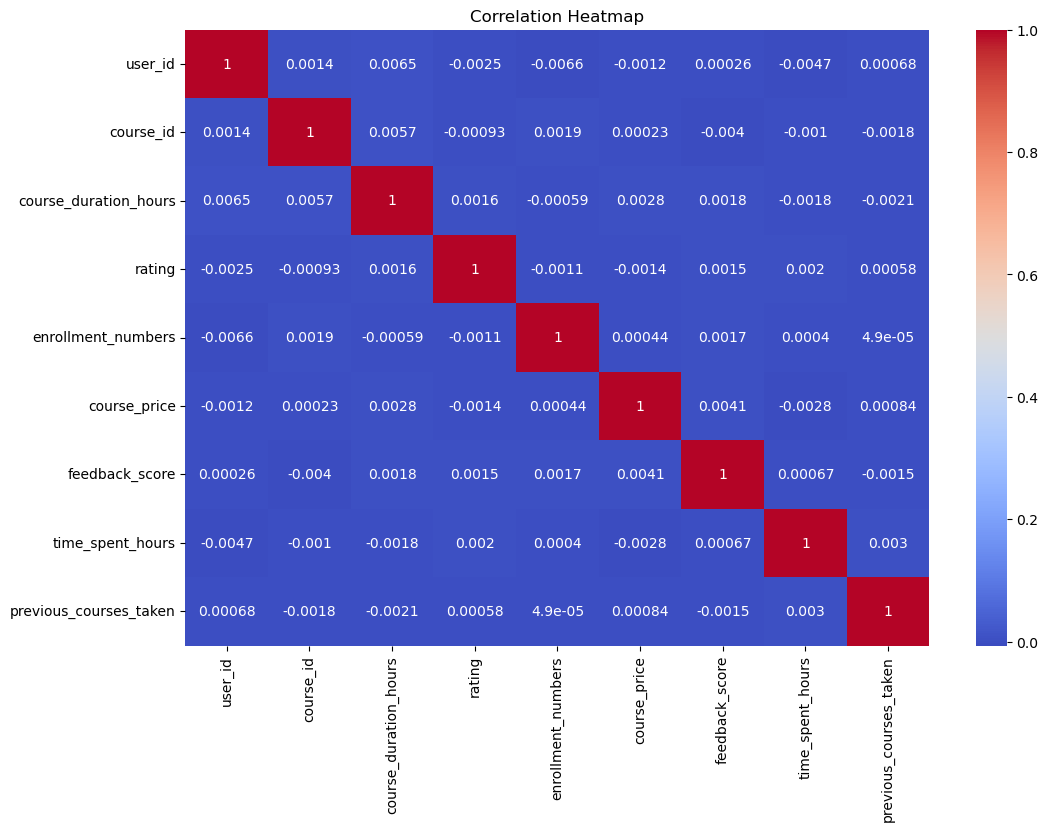

In [30]:
##Correlation Heatmap
numeric_df = df.select_dtypes(include=['int64','float64'])
plt.figure(figsize=(12,8))
sns.heatmap(numeric_df.corr(),
            annot=True,
            cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()

# EDA Summary

- Ratings are mostly above average.
- Beginner courses are the most common.
- Most courses offer certificates.
- Many courses provide study materials.
- Course prices vary widely.
- Enrollment numbers differ significantly.
- Feedback scores are generally positive.
- Only weak correlations exist among most numerical variables.

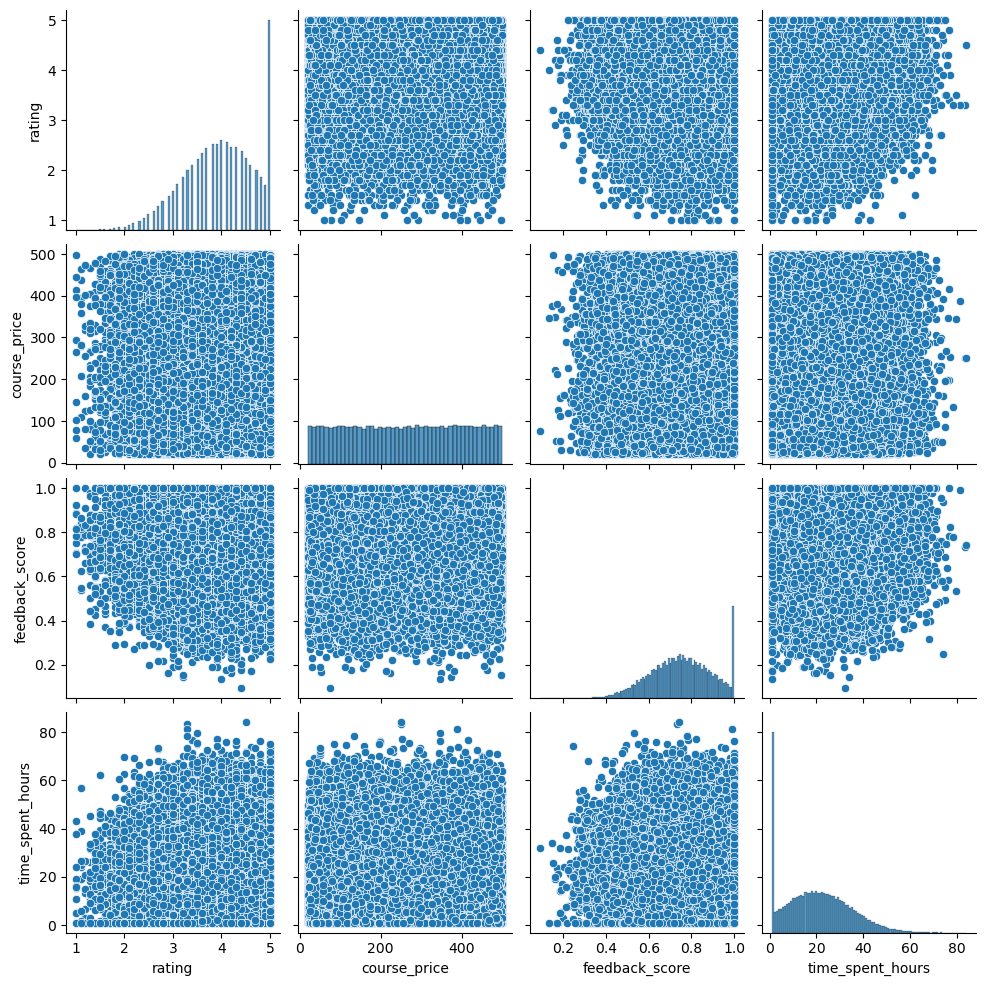

In [31]:
##Pairplot
sns.pairplot(
    numeric_df[['rating',
                'course_price',
                'feedback_score',
                'time_spent_hours']]
)
plt.show()

In [32]:
df

,user_id,course_id,course_name,instructor,course_duration_hours,certification_offered,difficulty_level,rating,enrollment_numbers,course_price,feedback_score,study_material_available,time_spent_hours,previous_courses_taken
0,15796,9366,Python for Beginners,Emma Harris,39.1,Yes,Beginner,5.0,21600,317.50,0.797,Yes,17.60,4
1,861,1928,Cybersecurity for Professionals,Alexander Young,36.3,Yes,Beginner,4.3,15379,40.99,0.770,Yes,28.97,9
2,38159,9541,DevOps and Continuous Deployment,Dr. Mia Walker,13.4,Yes,Beginner,3.9,6431,380.81,0.772,Yes,52.44,4
3,44733,3708,Project Management Fundamentals,Benjamin Lewis,58.3,Yes,Beginner,3.1,48245,342.80,0.969,No,22.29,6
4,11285,3361,Ethical Hacking Masterclass,Daniel White,30.8,Yes,Beginner,2.8,34556,381.01,0.555,Yes,22.01,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,10647,5466,Graphic Design with Canva,Emma Harris,17.3,Yes,Beginner,3.9,49101,485.34,0.838,Yes,16.35,3
99996,13800,2623,Stock Market and Trading Strategies,Dr. John Smith,68.4,Yes,Beginner,3.5,35107,162.80,0.922,Yes,41.94,7
99997,47131,1556,Networking and System Administration,Dr. John Smith,73.8,Yes,Beginner,4.3,12146,24.02,0.990,Yes,15.87,5
99998,49654,6001,Graphic Design with Canva,Daniel White,30.3,Yes,Beginner,3.5,9933,402.24,0.630,Yes,21.05,4


In [33]:
##select features
features = [
    'course_name',
    'instructor',
    'difficulty_level',
    'certification_offered',
    'study_material_available'
]

In [34]:
##Convert Everything to String
for col in features:
    df[col] = df[col].astype(str)

In [35]:
##Create a Combined Feature Column
df['combined_features'] = (
    df['course_name'] + " " +
    df['instructor'] + " " +
    df['difficulty_level'] + " " +
    df['certification_offered'] + " " +
    df['study_material_available']
)

In [36]:
##Check the New Column
df[['course_name','combined_features']].head()

,course_name,combined_features
0,Python for Beginners,Python for Beginners Emma Harris Beginner Yes Yes
1,Cybersecurity for Professionals,Cybersecurity for Professionals Alexander Youn...
2,DevOps and Continuous Deployment,DevOps and Continuous Deployment Dr. Mia Walke...
3,Project Management Fundamentals,Project Management Fundamentals Benjamin Lewis...
4,Ethical Hacking Masterclass,Ethical Hacking Masterclass Daniel White Begin...


In [37]:
##Convert Text to Numbers (TF-IDF)
tfidf = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf.fit_transform(df['combined_features'])

In [38]:
##Check Matrix Shape
tfidf_matrix.shape

(100000, 103)

In [39]:
##Create the TF-IDF Matrix
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf.fit_transform(df['combined_features'])

In [40]:
from sklearn.neighbors import NearestNeighbors

In [41]:
##Build the Model
model = NearestNeighbors(
    metric='cosine',
    algorithm='brute',
    n_neighbors=6
)

model.fit(tfidf_matrix)

,n_neighbors,6
,radius,1.0
,algorithm,'brute'
,leaf_size,30
,metric,'cosine'
,p,2
,metric_params,None
,n_jobs,None


In [42]:
##Create an Index
indices = pd.Series(df.index, index=df['course_name']).drop_duplicates()

In [43]:
##Recommendation Function
def recommend_courses(course_name):
    
    if course_name not in indices:
        return "Course not found."

    idx = indices[course_name]

    distances, neighbors = model.kneighbors(
    tfidf_matrix[idx],
    n_neighbors=6
    )

    recommended = neighbors.flatten()[1:]

    return df.iloc[recommended][[
        'course_name',
        'instructor',
        'difficulty_level',
        'rating'
    ]]

In [44]:
##Test It
df['course_name'].unique()[:10]

array(['Python for Beginners', 'Cybersecurity for Professionals',
       'DevOps and Continuous Deployment',
       'Project Management Fundamentals', 'Ethical Hacking Masterclass',
       'Networking and System Administration',
       'Personal Finance and Wealth Building',
       'Blockchain and Decentralized Applications',
       'Graphic Design with Canva', 'Fitness and Nutrition Coaching'],
      dtype=object)

In [45]:
recommend_courses("Python Programming")

'Course not found.'

Week 2: Model Evaluation

In [46]:
##Test the Recommendation System
df['course_name'].drop_duplicates().sample(10, random_state=42)

0                     Python for Beginners
46     Stock Market and Trading Strategies
23       Mobile App Development with Swift
1          Cybersecurity for Professionals
10               Graphic Design with Canva
6     Networking and System Administration
14           Photography and Video Editing
3          Project Management Fundamentals
49       Fundamentals of Digital Marketing
30         Data Visualization with Tableau
Name: course_name, dtype: object

In [47]:
recommend_courses("Python Programming")

'Course not found.'

In [48]:
recommend_courses("Stock Market and Trading Strategies")

,course_name,instructor,difficulty_level,rating
52380,Stock Market and Trading Strategies,Emma Harris,Beginner,4.8
38840,Stock Market and Trading Strategies,Emma Harris,Beginner,3.7
68270,Stock Market and Trading Strategies,Emma Harris,Beginner,4.2
61506,Stock Market and Trading Strategies,Emma Harris,Beginner,4.8
86867,Stock Market and Trading Strategies,Emma Harris,Beginner,4.1
...,...,...,...,...
79453,Stock Market and Trading Strategies,Dr. John Smith,Beginner,3.9
53666,Stock Market and Trading Strategies,Dr. John Smith,Beginner,5.0
82601,Stock Market and Trading Strategies,Dr. John Smith,Beginner,4.1
67600,Stock Market and Trading Strategies,Dr. John Smith,Beginner,4.9


In [49]:
##Display More Information
def recommend_courses(course_name):
    
    if course_name not in indices:
        return "Course not found."

    idx = indices[course_name]

    distances, neighbors = model.kneighbors(tfidf_matrix[idx])

    recommended = neighbors.flatten()[1:6]

    return df.iloc[recommended][[
        'course_name',
        'instructor',
        'difficulty_level',
        'rating',
        'course_duration_hours',
        'course_price'
    ]]

In [50]:
##Save the Model
import pickle
pickle.dump(model, open("models/recommendation_model.pkl", "wb"))
pickle.dump(tfidf, open("models/tfidf_vectorizer.pkl", "wb"))
pickle.dump(df, open("models/course_dataframe.pkl", "wb"))

In [51]:
##Test Loading the Model
loaded_model = pickle.load(open("models/recommendation_model.pkl", "rb"))
loaded_model

,n_neighbors,6
,radius,1.0
,algorithm,'brute'
,leaf_size,30
,metric,'cosine'
,p,2
,metric_params,None
,n_jobs,None


# Model Evaluation

The recommendation system was built using TF-IDF Vectorization and the Nearest Neighbors algorithm with cosine distance.

Evaluation was performed by testing recommendations for multiple courses.

Observations:
- Recommended courses belonged to similar domains.
- Courses had similar difficulty levels.
- Instructor and certification information contributed to recommendation quality.
- The Nearest Neighbors approach efficiently handled the large dataset without requiring a full similarity matrix.

In [52]:
df.to_csv("final_dataset.csv", index=False)

In [53]:
df

,user_id,course_id,course_name,instructor,course_duration_hours,certification_offered,difficulty_level,rating,enrollment_numbers,course_price,feedback_score,study_material_available,time_spent_hours,previous_courses_taken,combined_features
0,15796,9366,Python for Beginners,Emma Harris,39.1,Yes,Beginner,5.0,21600,317.50,0.797,Yes,17.60,4,Python for Beginners Emma Harris Beginner Yes Yes
1,861,1928,Cybersecurity for Professionals,Alexander Young,36.3,Yes,Beginner,4.3,15379,40.99,0.770,Yes,28.97,9,Cybersecurity for Professionals Alexander Youn...
2,38159,9541,DevOps and Continuous Deployment,Dr. Mia Walker,13.4,Yes,Beginner,3.9,6431,380.81,0.772,Yes,52.44,4,DevOps and Continuous Deployment Dr. Mia Walke...
3,44733,3708,Project Management Fundamentals,Benjamin Lewis,58.3,Yes,Beginner,3.1,48245,342.80,0.969,No,22.29,6,Project Management Fundamentals Benjamin Lewis...
4,11285,3361,Ethical Hacking Masterclass,Daniel White,30.8,Yes,Beginner,2.8,34556,381.01,0.555,Yes,22.01,5,Ethical Hacking Masterclass Daniel White Begin...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,10647,5466,Graphic Design with Canva,Emma Harris,17.3,Yes,Beginner,3.9,49101,485.34,0.838,Yes,16.35,3,Graphic Design with Canva Emma Harris Beginner...
99996,13800,2623,Stock Market and Trading Strategies,Dr. John Smith,68.4,Yes,Beginner,3.5,35107,162.80,0.922,Yes,41.94,7,Stock Market and Trading Strategies Dr. John S...
99997,47131,1556,Networking and System Administration,Dr. John Smith,73.8,Yes,Beginner,4.3,12146,24.02,0.990,Yes,15.87,5,Networking and System Administration Dr. John ...
99998,49654,6001,Graphic Design with Canva,Daniel White,30.3,Yes,Beginner,3.5,9933,402.24,0.630,Yes,21.05,4,Graphic Design with Canva Daniel White Beginne...
